# Load libraries

In [1]:
import numpy as np
import itertools, pandas as pd
from models import LinearModel, ChoquetModel, LipschitzModel
from tests import (
    ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2,
    ZDT1_Shifted, ZDT2_Shifted, ZDT2_Combined,
    Kursawe, Fon, Sch1, Sch2,
    Ackley01, Schwefel04, Gulf,
    ExtendedProblem, WFG
)

from agg import (
    Product, Drastic, Lukasiewicz,
    SchweizerSklar, Frank,
    QAM, ConjunctiveThreePi
)

import matplotlib.pyplot as plt
from utils import evaluate, visualise_weights

# Modelling: Problems

## ZDT & DTLZ

In [2]:
# ZDT calling
# linear_model = LinearModel(problem = ZDT2(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# # DTLZ calling
# linear_model = LinearModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42)
# choquet_model = ChoquetModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [3]:
# Self-constructed calling
# linear_model = LinearModel(problem = ZDT2_Swapped(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2_Swapped(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2_Swapped(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# linear_model = LinearModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [4]:
# extended_problem = ExtendedProblem(
#     problems = [ZDT2(n_dim = 5),
#                 Drastic([ZDT2(n_dim = 5)]),
#                 ],
#     order = None)

In [5]:
# linear_model = LinearModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# linear_model = LinearModel(problem = extended_problem, max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = extended_problem, max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = extended_problem, max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [6]:
# WFG calling
linear_model = LinearModel(problem = WFG(name = "wfg1", n_dim = 10, n_obj = 2), max_iter = 5, random_state = 42)
choquet_model = ChoquetModel(problem = WFG(name = "wfg1", n_dim = 10, n_obj = 2), max_iter = 5, random_state = 42, method = 2)
slip_model = LipschitzModel(problem = WFG(name = "wfg1", n_dim = 10, n_obj = 2), max_iter = 5, random_state = 42,
                            type = "global_mon", num_k = 2)

# Modelling: Solve

In [7]:
# Let them solve
linear_model.solve()
choquet_model.solve()
slip_model.solve()

# Summary their performance metrics

print(f"LinearModel :  PF {linear_model.PF.shape}  PS {linear_model.PS.shape}")
print(f"ChoquetModel:  PF {choquet_model.PF.shape} PS {choquet_model.PS.shape}")
print(f"LipschitzModel:  PF {slip_model.PF.shape} PS {slip_model.PS.shape}")
evaluate([linear_model, choquet_model, slip_model])

LinearModel :  PF (245, 2)  PS (245, 10)
ChoquetModel:  PF (211, 2) PS (211, 10)
LipschitzModel:  PF (273, 2) PS (273, 10)


,hypervolume,n_func_eval,n_non_dominated,n_iter,wallclock_time
LinearModel,4.517616,89057,245,5,29.690169
ChoquetModel,4.556507,99264,211,5,46.389651
LipschitzModel,4.458521,57781,273,5,90.814299


# Model visualisation

In [8]:
# for kind in ["symmetric", "absolute", "norm"]:
#     visualise_weights(choquet_model, kind = kind);

In [9]:
# linear_model.visualise("true_pf");

## Linear Model

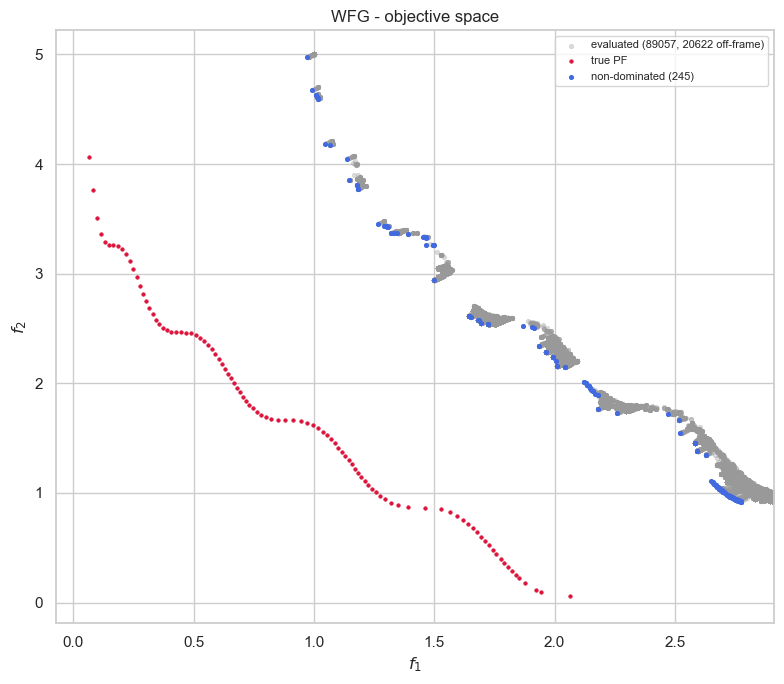

In [10]:
linear_model.visualise("objective");

In [11]:
linear_model.visualise("learning", show = False)

In [12]:
linear_model.visualise("learning", plot_scalarisation = True, show = False)

## Choquet Model

In [13]:
np.all((choquet_model.dec_hist >= 0) & (choquet_model.dec_hist <= 1))

np.True_

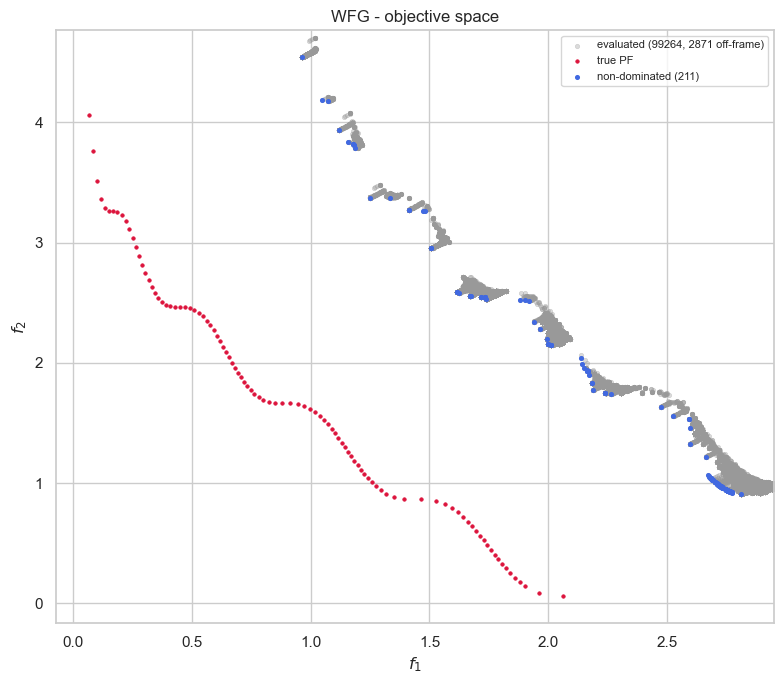

In [14]:
choquet_model.visualise("objective");

In [15]:
choquet_model.visualise("learning", show = False)

In [16]:
choquet_model.visualise("learning", plot_scalarisation = True, show = False)

## Lipschitz Model

In [17]:
np.all((slip_model.dec_hist >= 0) & (slip_model.dec_hist <= 1))

np.True_

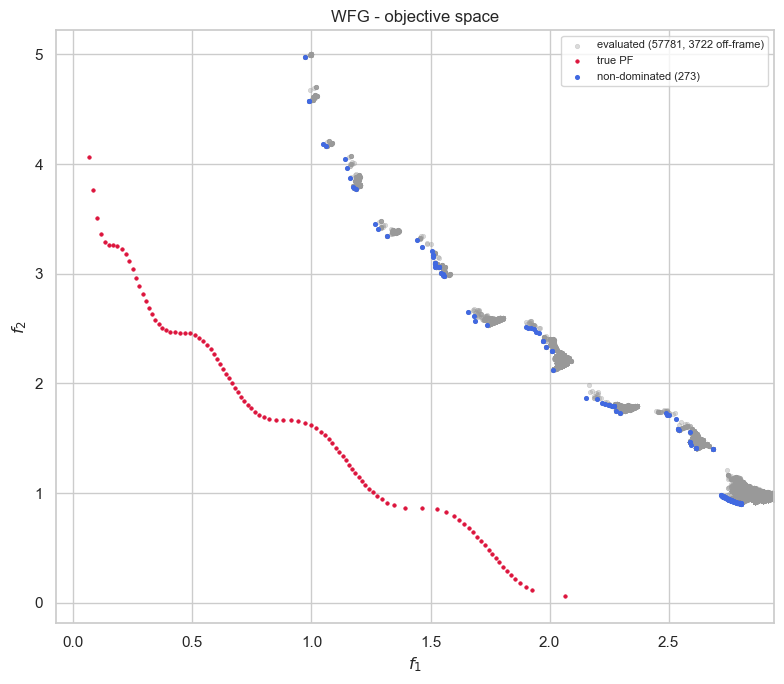

In [18]:
slip_model.visualise("objective");

In [19]:
slip_model.visualise("learning", show = False)

In [20]:
slip_model.visualise("learning", plot_scalarisation = True, show = False)

# Pareto Front and Pareto Set statistics

This section displays the statistics of the Pareto front and Pareto set found by the above-mentioned models. Note that, these are the set of non-dominated solutions, not all the iterates obtained throughout their runs.

In [21]:
import seaborn as sns


def plot_distributions(arrays, symbol, title):
    """Box plot and per-component ECDFs of each model's points; arrays maps model name -> (n_points, n_components)."""
    long = pd.concat(
        [pd.DataFrame(a).rename(columns = lambda k: f"${symbol}_{{{k + 1}}}$")
           .melt(var_name = "component", value_name = "value")
           .assign(model = f"{name} (n={len(a)})")
         for name, a in arrays.items()],
        ignore_index = True,
    )
    n_comp = long["component"].nunique()

    fig, ax = plt.subplots(figsize = (max(6, 1.6 * n_comp), 4))
    sns.boxplot(data = long, x = "component", y = "value", hue = "model", ax = ax,
                fliersize = 2, linewidth = 0.8)
    ax.set(xlabel = None, ylabel = f"${symbol}$", title = f"{title}: distribution per component")
    sns.move_legend(ax, "upper left", bbox_to_anchor = (1, 1), frameon = False)
    plt.show()

    g = sns.displot(long, x = "value", hue = "model", col = "component", kind = "ecdf",
                    col_wrap = min(n_comp, 5), height = 2.8, aspect = 1)
    g.set_titles("{col_name}")
    g.set_axis_labels(f"${symbol}$", "ECDF")
    g.figure.suptitle(f"{title}: empirical CDF per component", y = 1.04)
    plt.show()

## Pareto Front

In [22]:
# arr = {
#     "baseline": linear_model.PF,
#     "cas": choquet_model.PF,
#     "las": slip_model.PF
# }

arr = {
    "baseline": linear_model.obj_hist,
    "cas": choquet_model.obj_hist,
    "las": slip_model.obj_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                         cas                         las  \
k                 0             1             0             1             0   
count  89057.000000  89057.000000  99264.000000  99264.000000  57781.000000   
mean       2.500597      1.543815      2.538462      1.479421      2.773210   
std        0.508615      0.742210      0.505033      0.773927      0.291466   
min        0.972754      0.920164      0.962031      0.907664      0.973935   
25%        2.017178      0.972257      2.046529      0.968412      2.814743   
50%        2.821454      1.026528      2.836964      0.995891      2.852244   
75%        2.908300      2.252997      2.890159      2.189288      2.902241   
max        3.000000      5.000000      3.000000      5.000000      2.999109   

model                
k                 1  
count  57781.000000  
mean       1.132401  
std        0.458871  
min        0.903095  
25%        0.967298  
50%        0.985855  
75%        1.011340  
max        5.000000

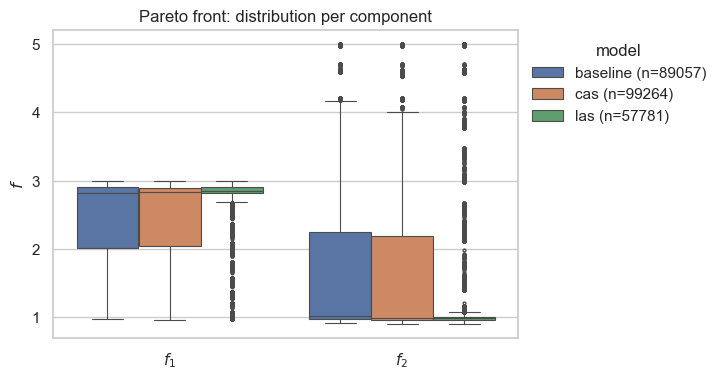

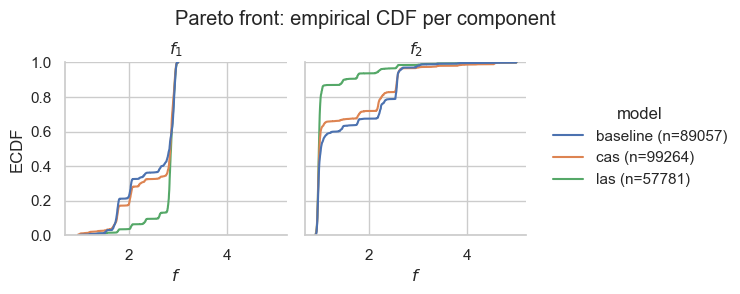

In [23]:
plot_distributions(arr, "f", "Pareto front")

## Pareto Set

In [24]:
# arr = {
#     "baseline": linear_model.PS,
#     "cas": choquet_model.PS,
#     "las": slip_model.PS
# }

arr = {
    "baseline": linear_model.dec_hist,
    "cas": choquet_model.dec_hist,
    "las": slip_model.dec_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                                                          \
k                 0             1             2             3             4   
count  89057.000000  89057.000000  89057.000000  89057.000000  89057.000000   
mean       0.431035      0.442618      0.409904      0.400736      0.513968   
std        0.296407      0.310806      0.323883      0.335590      0.282301   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.169743      0.151862      0.059552      0.018955      0.295659   
50%        0.447371      0.430637      0.397882      0.381974      0.500000   
75%        0.668667      0.736794      0.735077      0.686012      0.770379   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

model                                                                        \
k                 5             6             7             8             9   
count  89057.000000  89057.000000  89057.000000  89057.000000  89057.000000   
mean       0.516948      0.491375      0.477998      0.469365      0.485442   
std        0.268583      0.272676      0.268916      0.280057      0.278654   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.338812      0.307044      0.328669      0.270329      0.317279   
50%        0.489244      0.430888      0.432327      0.427332      0.443062   
75%        0.745084      0.734968      0.679812      0.700555      0.723835   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

model  ...           las                                            \
k      ...             0             1             2             3   
count  ...  57781.000000  57781.000000  57781.000000  57781.000000   
mean   ...      0.456690      0.429812      0.403588      0.374861   
std    ...      0.314044      0.311376      0.297422      0.306715   
min    ...      0.000000      0.000000      0.000000      0.000000   
25%    ...      0.158290      0.126347      0.135755      0.094509   
50%    ...      0.470780      0.400654      0.378422      0.339850   
75%    ...      0.722082      0.735633      0.647514      0.618541   
max    ...      1.000000      1.000000      1.000000      1.000000   

model                                                                        \
k                 4             5             6             7             8   
count  57781.000000  57781.000000  57781.000000  57781.000000  57781.000000   
mean       0.476111      0.514139      0.477275      0.453916      0.459163   
std        0.276042      0.246888      0.259832      0.235061      0.259479   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.224534      0.349992      0.288144      0.304902      0.292430   
50%        0.473933      0.489502      0.420767      0.403046      0.367975   
75%        0.695423      0.707478      0.684807      0.626317      0.672332   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

model                
k                 9  
count  57781.000000  
mean       0.450764  
std        0.244803  
min        0.000000  
25%        0.339114  
50%        0.370319  
75%        0.593040  
max        1.000000  

[8 rows x 30 columns]

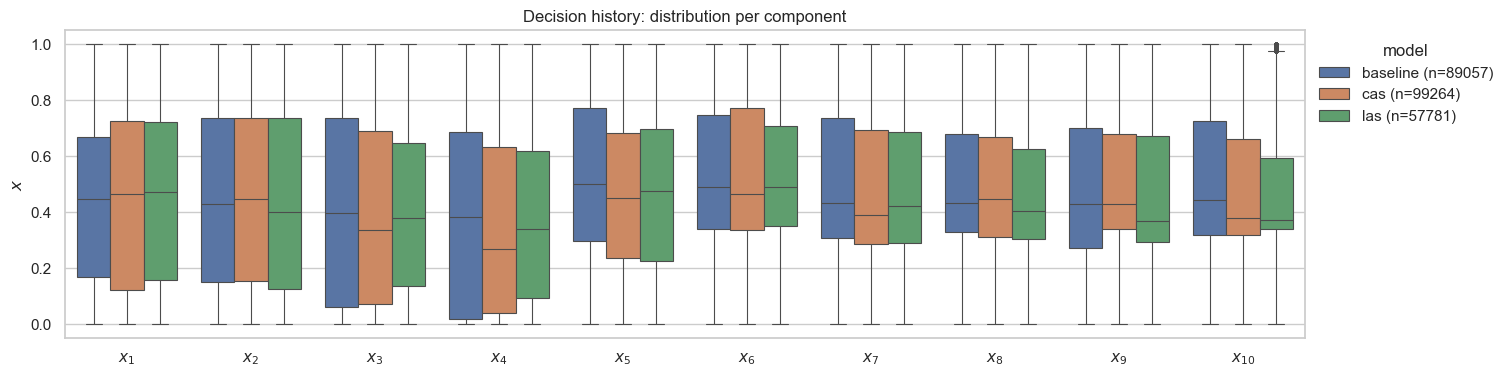

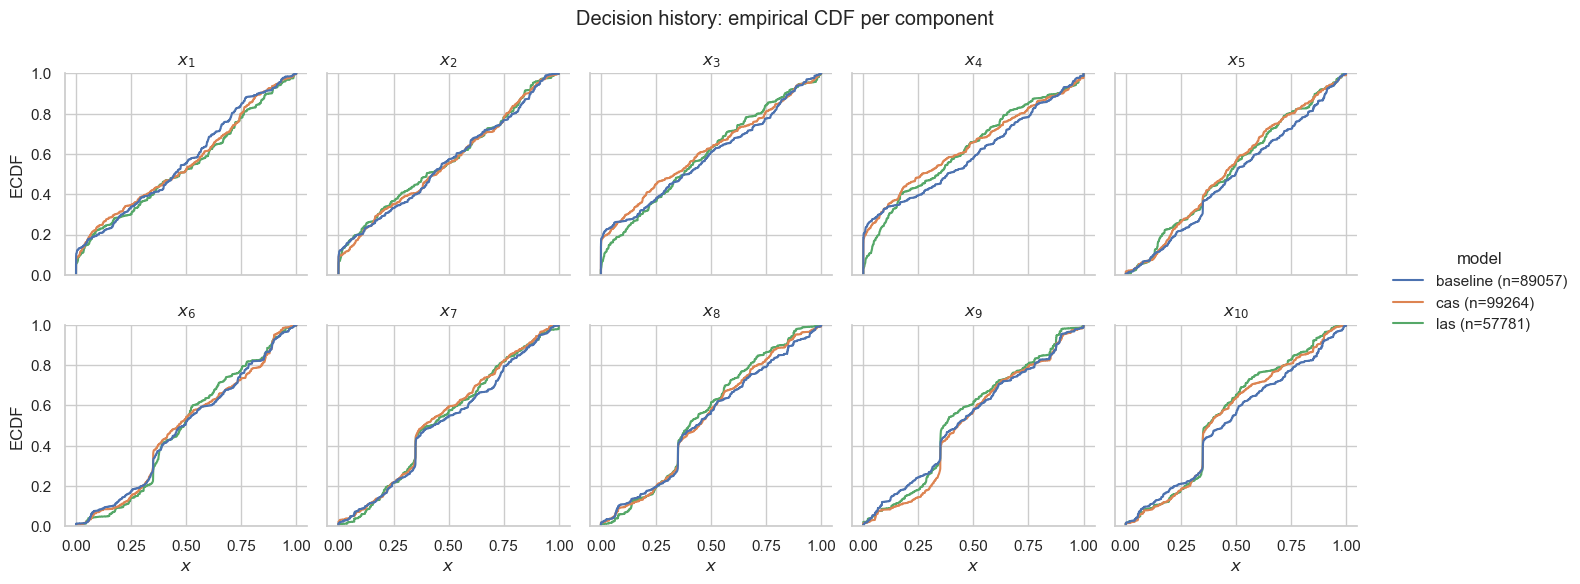

In [25]:
plot_distributions(arr, "x", "Decision history")

# Benchmark

Every configuration is solved by both models from the same seed, then scored by `evaluate()` against one shared reference point.

- **ZDT1/2/3** are 2-objective by construction, so they appear once per `n_dim` and ignore `obj_dims`.
- **DTLZ1/2** take `n_obj`, and are skipped when `n_dim <= n_obj` - there would be no tail variables left to carry `g`.
- Hypervolume is comparable **within** a row group only; the reference point differs between configurations, so never compare it across problems or dimensions.

In [26]:
# dec_dims   = [10, 20]
# obj_dims   = [2, 3, 4, 5]
# max_iter   = 50
# model_list = [LinearModel, ChoquetModel, LipschitzModel]
# prob_list  = [ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2]


# def build(problem, n_dim, n_obj):
#     """This grid cell's problem, or None if the combination does not exist: ZDT is 2-objective by
#        construction, and DTLZ needs n_dim > n_obj to leave tail variables to carry g."""
#     if problem in (ZDT1, ZDT2, ZDT3):
#         return problem(n_dim = n_dim) if n_obj == 2 else None
#     return problem(n_dim = n_dim, n_obj = n_obj) if n_dim > n_obj else None


# rows = []
# for problem, n_dim, n_obj in itertools.product(prob_list, dec_dims, obj_dims):
#     prob = build(problem, n_dim, n_obj)
#     if prob is None:
#         continue

#     fitted = [model(problem = prob, max_iter = max_iter, random_state = 42,
#                     **(dict(method = 2) if model is ChoquetModel else {}))
#               for model in model_list]
#     for m in fitted:
#         m.solve()

#     # evaluate() scores the pair against one shared reference point, and already times each solve
#     rows.append(evaluate(fitted).assign(problem = problem.__name__, n_dim = n_dim,
#                                         n_obj = prob.n_obj))
#     print(problem.__name__, f"n_dim={n_dim}", f"n_obj={prob.n_obj}",
#           dict(rows[-1]["wallclock_time"].round(1)))

# results = (pd.concat(rows).rename_axis("model").reset_index()
#              .set_index(["problem", "n_dim", "n_obj", "model"]).sort_index())
# results

In [27]:
# # hypervolume only compares within a configuration, so pick a winner per row
# hv = results["hypervolume"].unstack("model")
# hv.assign(winner = hv.idxmax(1), gap_pct = 100 * (hv.max(1) - hv.min(1)) / hv.max(1)).round(4)